# Capstone: MCP Tool-Call Inference — Gemma vs OpenAI vs Llama

**Student:** Aravind K. Sastry  
**Course / Instructor:** *Complete before submission*  
**Date:** *Complete before submission*  
**Repository:** https://github.com/Aravind-k-sastry/capstone_nlp_erp/

**Purpose:** Evaluate how accurately three LLM services infer the MCP tool-call plan and parameters from the `user_prompt` field. The gold labels are in `reference_tool_calls_json`. **No ERP tools are executed.**

**Run order:** Run cells from top to bottom. API tests and paid validation calls are separately controlled; **all provider calls are disabled by default**. Provider API keys are supplied directly in the model registry; this notebook does not use Colab Secrets.

**Research design:** 60/20/20 train/validation/test **by conversation**, stratified by scenario family. All turns of a conversation stay in one split. Because examples within a family are templated, results measure performance on *new variations of known scenarios*, not generalization to unseen scenario families. Reserve test for the final locked evaluation.

**Score definitions:**
- **Routing:** exact required **tool multiset** match, with appropriate clarification/refusal behavior and no forbidden calls.
- **Completeness:** correctly supplied required parameter *paths* / all required parameter paths (a present but wrong value is complete, not precise).
- **Precision:** correctly valued predicted parameter paths / all predicted parameter paths (extra/hallucinated paths reduce precision).
- **No-tool clarification:** 100% for all three **only when** `calls=[]` and `behavior="clarify"`.
- **Aggregation:** routing = mean over rows; parameter completeness/precision = micro pooled field counts for applicable tool-call rows, plus separately reported clarification success. No-tool cases are excluded from pooled field denominators to avoid artificial inflation.

**Limitations:** Synthetic reference plans are structurally, not ERP-execution, validated. A fixed tool schema and review of disputed references are required before making confirmatory claims.

## Step 0 — Install dependencies and configure experiment

In [26]:
# Install all Python packages used by this notebook.
# -q = quiet, -U = upgrade to latest; the three provider SDKs are google-genai, openai and groq.
%pip -q install -U pandas numpy scikit-learn scipy matplotlib seaborn google-genai openai groq

Note: you may need to restart the kernel to use updated packages.


In [27]:
# Standard library + scientific stack imports used throughout the notebook.
import os, json, re, io, time, random, math, hashlib, sys, platform, urllib.request
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display
from scipy.stats import binomtest

# Fix all random seeds so splits, few-shot sampling and any sampling are reproducible.
SEED=42
random.seed(SEED); np.random.seed(SEED)

# Write all artifacts to /content on Colab, otherwise a local folder; create it if missing.
OUT=Path('/content/mcp_capstone_outputs') if Path('/content').exists() else Path('mcp_capstone_outputs')
OUT.mkdir(parents=True,exist_ok=True)
REPO='https://github.com/Aravind-k-sastry/capstone_nlp_erp'

# --- Experiment control switches (all paid/provider calls OFF by default) ---
RUN_API_TESTS=True      # Switch True only when intentionally testing provider connectivity.
RUN_VALIDATION=True     # Switch True only when ready for inference costs.
RUN_FINAL_TEST=True     # Do not enable until prompts/model settings are frozen.

# --- Run-size and rate-limit knobs ---
MAX_VALIDATION_ROWS=None # Use 5 for pilot, None for all validation turns.
MAX_TEST_ROWS=None       # Cap test rows; None = all test turns.
MAX_EXAMPLES_PER_FAMILY=1 # Few-shot examples drawn per scenario family.
MAX_TOTAL_EXAMPLES=20     # Hard cap on total few-shot conversations.
MAX_OUTPUT_TOKENS=1400    # Max tokens each model may generate per call.
RETRIES=2                 # Extra attempts on failure.
SLEEP_SECONDS=0.35        # Pause between calls to respect rate limits.

print('Python',platform.python_version(),'pandas',pd.__version__,'output directory',OUT)

Python 3.13.6 pandas 3.1.0 output directory mcp_capstone_outputs


## Step 1 — Load dataset directly from GitHub

We use the **raw** CSV and record a SHA-256 hash. If the repository branch/path changes, edit `DATA_URLS`. If download fails, Colab offers a CSV upload. The original dataframe is never modified.

In [28]:
# Candidate raw-CSV URLs: try the 'main' branch first, then 'master' as a fallback.
DATA_URLS=[
 'https://raw.githubusercontent.com/Aravind-k-sastry/capstone_nlp_erp/main/data/p2p_conversations.csv',
 'https://raw.githubusercontent.com/Aravind-k-sastry/capstone_nlp_erp/master/data/p2p_conversations.csv'
]
raw=None; source=None
# Try each URL; accept the first that downloads AND has the required columns.
for url in DATA_URLS:
    try:
        with urllib.request.urlopen(url,timeout=25) as r: candidate=r.read()
        trial=pd.read_csv(io.BytesIO(candidate))
        if {'conversation_id','turn_id','user_prompt','reference_tool_calls_json'}.issubset(trial.columns):
            raw=candidate; source=url; break
    except Exception as e: print('GitHub attempt failed:',type(e).__name__,str(e)[:120])
# If no URL worked, fall back to a manual CSV upload (Colab only).
if raw is None:
    from google.colab import files
    print('Upload the CSV from your GitHub repository.')
    uploads=files.upload()
    selected=next((k for k in uploads if k.lower().endswith('.csv')),None)
    if not selected: raise RuntimeError('No CSV uploaded.')
    raw=uploads[selected];source='manual upload: '+selected
# Parse into a dataframe and record a SHA-256 of the raw bytes for provenance/reproducibility.
original_df=pd.read_csv(io.BytesIO(raw))
DATA_SHA256=hashlib.sha256(raw).hexdigest()
print('Source:',source,'SHA256:',DATA_SHA256)
print('Original shape:',original_df.shape,'Conversations:',original_df.conversation_id.nunique())
display(original_df.head(3))

Source: https://raw.githubusercontent.com/Aravind-k-sastry/capstone_nlp_erp/main/data/p2p_conversations.csv SHA256: 43446df0508b9ee2c5bd7bb91ae81a993dab1e5e6feb04c7d090a34bca415e2d
Original shape: (420, 10) Conversations: 400


,conversation_id,turn_id,conversation_context_json,user_prompt,expected_behavior,reference_tool_calls_json,expected_outcome_json,scenario_initial_state_json,validation_status,notes
0,P2P-0001,P2P-0001-T01,[],Create a draft purchase order for 23 units of ...,execute,"[{""tool"": ""create_purchase_order"", ""arguments""...","{""expected_behavior"": ""execute"", ""expected_sta...","{""suppliers"": {""SUP-004"": {""status"": ""active""}...",structural_validated_unexecuted,Synthetic; requires ERP execution and semantic...
1,P2P-0002,P2P-0002-T01,[],Create a draft purchase order for 36 units of ...,execute,"[{""tool"": ""create_purchase_order"", ""arguments""...","{""expected_behavior"": ""execute"", ""expected_sta...","{""suppliers"": {""SUP-007"": {""status"": ""active""}...",structural_validated_unexecuted,Synthetic; requires ERP execution and semantic...
2,P2P-0003,P2P-0003-T01,[],Create a draft purchase order for 49 units of ...,execute,"[{""tool"": ""create_purchase_order"", ""arguments""...","{""expected_behavior"": ""execute"", ""expected_sta...","{""suppliers"": {""SUP-010"": {""status"": ""active""}...",structural_validated_unexecuted,Synthetic; requires ERP execution and semantic...


## Step 1A — Cell 1: Dataset overview and quality assessment

In [29]:
# ============================================================
# STEP 1A — EXPLORATORY DATA ANALYSIS (EDA)
# CELL 1: Dataset Structure, Quality and Descriptive Statistics
#
# Run AFTER Step 1 (Dataset Loading)
# Run BEFORE Step 2 (Data Preprocessing)
#
# This cell is READ-ONLY and does not modify the original data.
# ============================================================

import pandas as pd
import numpy as np
import json
from collections import Counter

# ------------------------------------------------------------
# 1. Create a copy of the raw dataset
# ------------------------------------------------------------

eda_df = original_df.copy(deep=True)

print("=" * 70)
print("STEP 1A — DATASET OVERVIEW AND QUALITY ASSESSMENT")
print("=" * 70)

print(f"\nTotal records (turns): {len(eda_df):,}")
print(f"Total columns: {eda_df.shape[1]}")

if "conversation_id" in eda_df.columns:
    print(
        "Unique conversations:",
        eda_df["conversation_id"].nunique()
    )

if "turn_id" in eda_df.columns:
    print(
        "Unique turn IDs (not necessarily globally unique):",
        eda_df["turn_id"].nunique()
    )


# ------------------------------------------------------------
# 2. Utility functions for nested JSON / Python objects
# ------------------------------------------------------------

def normalize_value(value):
    """
    Convert nested values into stable, hashable representations.

    Supports:
    - dictionaries
    - lists
    - sets
    - numpy arrays
    - scalar values
    - missing values

    Does not modify the original dataset.
    """

    if isinstance(value, dict):
        return (
            "dict",
            json.dumps(
                value,
                sort_keys=True,
                ensure_ascii=False,
                default=str
            )
        )

    if isinstance(value, list):
        return (
            "list",
            json.dumps(
                value,
                sort_keys=True,
                ensure_ascii=False,
                default=str
            )
        )

    if isinstance(value, set):
        return (
            "set",
            tuple(sorted(map(str, value)))
        )

    if isinstance(value, np.ndarray):
        return (
            "ndarray",
            json.dumps(
                value.tolist(),
                sort_keys=True,
                default=str
            )
        )

    if value is None:
        return ("missing", None)

    try:
        if bool(pd.isna(value)):
            return ("missing", None)
    except (TypeError, ValueError):
        pass

    if isinstance(value, (str, int, float, bool, np.generic)):
        return (type(value).__name__, value)

    return (type(value).__name__, repr(value))


def is_missing(value):
    """
    Safely detect missing values without errors from
    lists, dictionaries or arrays.
    """

    if value is None:
        return True

    if isinstance(value, (dict, list, set, tuple, np.ndarray)):
        return False

    try:
        return bool(pd.isna(value))
    except (TypeError, ValueError):
        return False


def safe_nunique(series):
    """
    Count unique non-missing values, including nested objects.
    """
    values = [
        normalize_value(value)
        for value in series
        if not is_missing(value)
    ]

    return len(set(values))


# ------------------------------------------------------------
# 3. Column-level data quality summary
# ------------------------------------------------------------

print("\nCOLUMN STRUCTURE AND DATA QUALITY")
print("-" * 70)

column_summary = []

for column in eda_df.columns:

    series = eda_df[column]

    missing_count = sum(is_missing(v) for v in series)
    non_null_count = len(series) - missing_count

    column_summary.append({
        "column": column,
        "dtype": str(series.dtype),
        "non_null": non_null_count,
        "missing": missing_count,
        "missing_pct": round(
            (missing_count / len(series) * 100)
            if len(series) else 0,
            2
        ),
        "unique_values": safe_nunique(series)
    })

column_summary_df = pd.DataFrame(column_summary)

display(column_summary_df)


# ------------------------------------------------------------
# 4. Duplicate assessment
# ------------------------------------------------------------

print("\nDUPLICATE ASSESSMENT")
print("-" * 70)

# Normalize every value into a hashable representation.
# This is a temporary DataFrame used only for analysis.

duplicate_check_df = eda_df.apply(
    lambda col: col.map(normalize_value)
)

# Exact duplicates across every column
exact_duplicate_count = int(
    duplicate_check_df.duplicated().sum()
)

print("Exact duplicate rows:", exact_duplicate_count)

# Duplicate conversation-turn pairs
if {"conversation_id", "turn_id"}.issubset(eda_df.columns):

    duplicate_turn_count = int(
        duplicate_check_df.duplicated(
            subset=["conversation_id", "turn_id"]
        ).sum()
    )

    print(
        "Duplicate conversation-turn pairs:",
        duplicate_turn_count
    )

# Repeated prompts may be legitimate across different scenarios
if "user_prompt" in eda_df.columns:

    repeated_prompt_count = int(
        duplicate_check_df["user_prompt"].duplicated().sum()
    )

    print(
        "Repeated user prompts:",
        repeated_prompt_count
    )


# ------------------------------------------------------------
# 5. User prompt descriptive statistics
# ------------------------------------------------------------

if "user_prompt" in eda_df.columns:

    print("\nUSER PROMPT ANALYSIS")
    print("-" * 70)

    prompt_text = eda_df["user_prompt"].apply(
        lambda value: (
            value if isinstance(value, str) else ""
        )
    )

    prompt_word_counts = prompt_text.apply(
        lambda text: len(text.split())
    )

    prompt_character_counts = prompt_text.str.len()

    print("\nPrompt length statistics:")

    prompt_stats = pd.DataFrame({
        "word_count": prompt_word_counts,
        "character_count": prompt_character_counts
    })

    display(prompt_stats.describe().round(2))

    empty_prompt_count = int(
        prompt_text.str.strip().eq("").sum()
    )

    print(
        "\nEmpty or whitespace-only prompts:",
        empty_prompt_count
    )


# ------------------------------------------------------------
# 6. Expected agent behavior distribution
# ------------------------------------------------------------

if "expected_behavior" in eda_df.columns:

    print("\nEXPECTED AGENT BEHAVIOR DISTRIBUTION")
    print("-" * 70)

    behavior_distribution = (
        eda_df["expected_behavior"]
        .apply(
            lambda value: (
                "MISSING"
                if is_missing(value)
                else str(value)
            )
        )
        .value_counts()
        .rename_axis("expected_behavior")
        .reset_index(name="record_count")
    )

    behavior_distribution["percentage"] = (
        behavior_distribution["record_count"]
        / len(eda_df) * 100
    ).round(2) if len(eda_df) else 0

    display(behavior_distribution)


# ------------------------------------------------------------
# 7. JSON field validity assessment
# ------------------------------------------------------------

print("\nJSON FIELD VALIDITY")
print("-" * 70)

json_columns = [
    column
    for column in eda_df.columns
    if column.endswith("_json")
]


def check_json_status(value):
    """
    Classify JSON fields as:
    - Missing
    - Valid
    - Invalid

    Handles both serialized JSON strings and
    already-parsed Python dictionaries/lists.
    """

    if is_missing(value):
        return "Missing"

    if isinstance(value, str):

        if not value.strip():
            return "Missing"

        try:
            json.loads(value)
            return "Valid"
        except (ValueError, TypeError):
            return "Invalid"

    if isinstance(value, (dict, list)):
        return "Valid"

    return "Invalid"


json_quality_results = []

for column in json_columns:

    statuses = eda_df[column].apply(check_json_status)

    counts = statuses.value_counts()

    json_quality_results.append({
        "column": column,
        "valid": int(counts.get("Valid", 0)),
        "invalid": int(counts.get("Invalid", 0)),
        "missing": int(counts.get("Missing", 0)),
        "valid_pct": round(
            counts.get("Valid", 0) / len(eda_df) * 100,
            2
        ) if len(eda_df) else 0
    })

if json_quality_results:
    display(pd.DataFrame(json_quality_results))
else:
    print("No columns ending in '_json' were found.")


# ------------------------------------------------------------
# 8. Validation status distribution
# ------------------------------------------------------------

if "validation_status" in eda_df.columns:

    print("\nDATASET VALIDATION STATUS")
    print("-" * 70)

    validation_distribution = (
        eda_df["validation_status"]
        .apply(
            lambda value: (
                "MISSING"
                if is_missing(value)
                else str(value)
            )
        )
        .value_counts()
        .rename_axis("validation_status")
        .reset_index(name="record_count")
    )

    display(validation_distribution)


# ------------------------------------------------------------
# 9. Final EDA summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 1A — CELL 1 COMPLETED")
print("=" * 70)

print(f"Records analyzed: {len(eda_df):,}")
print(f"Columns analyzed: {eda_df.shape[1]}")
print(f"Exact duplicate rows: {exact_duplicate_count}")
print(f"JSON columns assessed: {len(json_columns)}")

print(
    "\nNo records were removed, modified, or deduplicated."
)
print(
    "The original dataset remains available for Step 2."
)


STEP 1A — DATASET OVERVIEW AND QUALITY ASSESSMENT

Total records (turns): 420
Total columns: 10
Unique conversations: 400
Unique turn IDs (not necessarily globally unique): 420

COLUMN STRUCTURE AND DATA QUALITY
----------------------------------------------------------------------


,column,dtype,non_null,missing,missing_pct,unique_values
0,conversation_id,str,420,0,0.0,400
1,turn_id,str,420,0,0.0,420
2,conversation_context_json,str,420,0,0.0,21
3,user_prompt,str,420,0,0.0,419
4,expected_behavior,str,420,0,0.0,3
5,reference_tool_calls_json,str,420,0,0.0,380
6,expected_outcome_json,str,420,0,0.0,137
7,scenario_initial_state_json,str,420,0,0.0,400
8,validation_status,str,420,0,0.0,1
9,notes,str,420,0,0.0,3



DUPLICATE ASSESSMENT
----------------------------------------------------------------------
Exact duplicate rows: 0
Duplicate conversation-turn pairs: 0
Repeated user prompts: 1

USER PROMPT ANALYSIS
----------------------------------------------------------------------

Prompt length statistics:


,word_count,character_count
count,420.00,420.00
mean,16.48,92.82
std,4.42,21.73
min,8.00,41.00
25%,15.00,79.00
50%,16.00,91.50
75%,18.00,106.00
max,27.00,138.00



Empty or whitespace-only prompts: 0

EXPECTED AGENT BEHAVIOR DISTRIBUTION
----------------------------------------------------------------------


...


JSON FIELD VALIDITY
----------------------------------------------------------------------


,column,valid,invalid,missing,valid_pct
0,conversation_context_json,420,0,0,100.0
1,reference_tool_calls_json,420,0,0,100.0
2,expected_outcome_json,420,0,0,100.0
3,scenario_initial_state_json,420,0,0,100.0



DATASET VALIDATION STATUS
----------------------------------------------------------------------


,validation_status,record_count
0,structural_validated_unexecuted,420



STEP 1A — CELL 1 COMPLETED
Records analyzed: 420
Columns analyzed: 10
Exact duplicate rows: 0
JSON columns assessed: 4

No records were removed, modified, or deduplicated.
The original dataset remains available for Step 2.


STEP 1A — SCENARIO AND MCP TOOL ANALYSIS


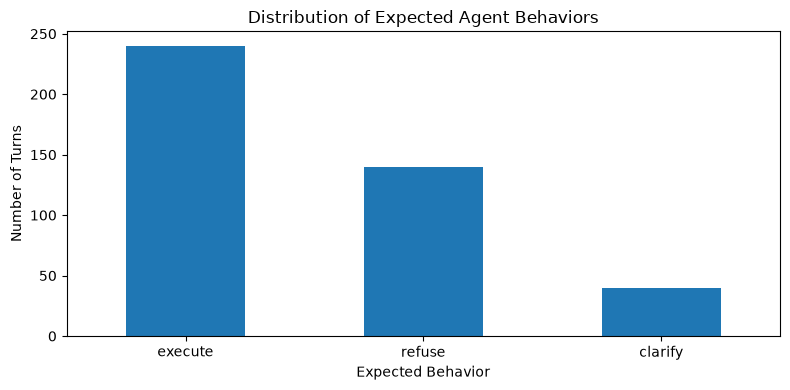


Reference tool calls per turn:


,tool_calls_per_turn
count,420.00
mean,1.71
std,1.03
min,0.00
25%,1.00
50%,2.00
75%,2.00
max,4.00


Turns with zero tool calls: 40
Turns with multiple tool calls: 220


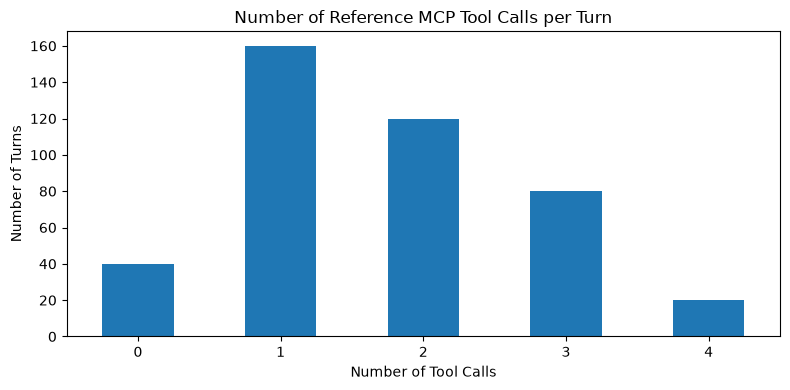


Reference MCP tool frequency:


,tool_name,frequency
0,get_purchase_order,240
1,create_purchase_order,80
2,create_goods_receipt,60
3,submit_purchase_order,40
4,check_approval_authority,40
5,find_supplier_invoice,40
6,get_goods_receipts,40
7,validate_invoice_match,40
8,create_purchase_requisition,20
9,update_purchase_order,20


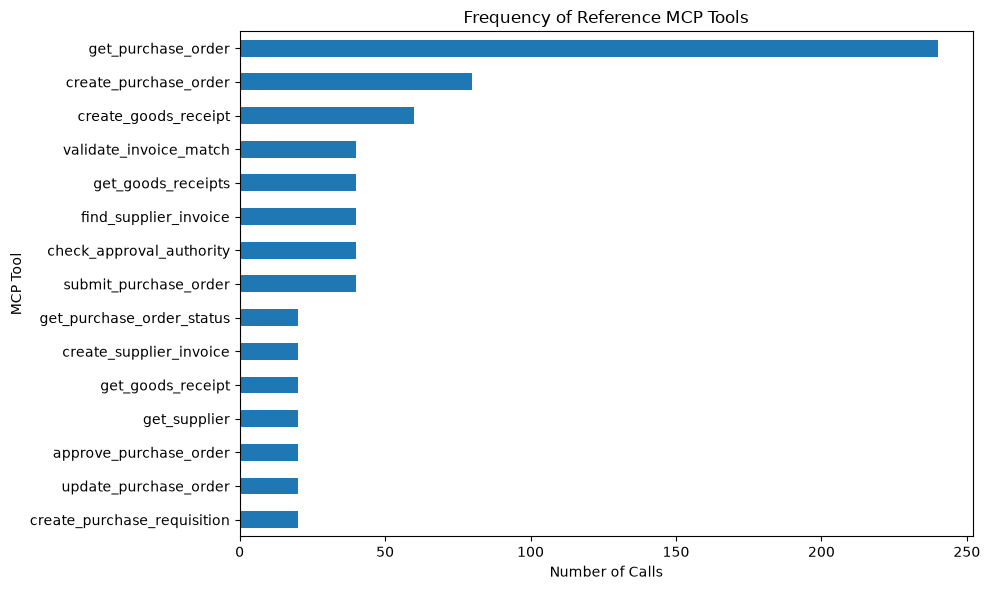


Turns per conversation:


,turns_per_conversation
count,400.00
mean,1.05
std,0.22
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,2.00


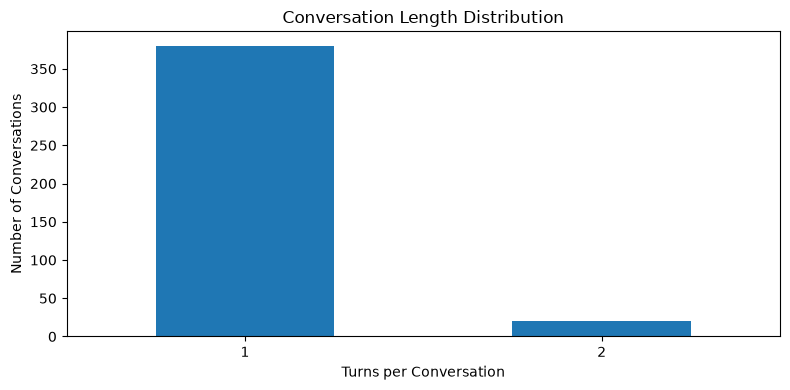


No explicit scenario-family column found. Scenario family may be encoded in conversation_id or another metadata field.

EDA Cell 2 completed — original dataset unchanged.


In [30]:

# ============================================================
# STEP 1A — EXPLORATORY DATA ANALYSIS (EDA)
# Cell 2: Scenario, MCP tool-call and conversation analysis
# ============================================================

import matplotlib.pyplot as plt
from collections import Counter

def parse_tool_calls(value):
    """Extract tool calls without modifying the original dataset."""
    try:
        parsed = (
            json.loads(value)
            if isinstance(value, str)
            else value
        )

        if isinstance(parsed, list):
            return parsed

        if isinstance(parsed, dict):
            for key in ("tool_calls", "calls"):
                if isinstance(parsed.get(key), list):
                    return parsed[key]

        return []

    except (ValueError, TypeError):
        return []


def get_tool_name(call):
    if not isinstance(call, dict):
        return None

    function = call.get("function", {})

    if isinstance(function, dict) and function.get("name"):
        return function["name"]

    return (
        call.get("tool_name")
        or call.get("name")
        or call.get("tool")
    )


print("=" * 65)
print("STEP 1A — SCENARIO AND MCP TOOL ANALYSIS")
print("=" * 65)

# 1. Expected behavior distribution
if "expected_behavior" in eda_df.columns:
    behavior_counts = (
        eda_df["expected_behavior"]
        .fillna("MISSING")
        .value_counts()
    )

    plt.figure(figsize=(8, 4))
    behavior_counts.plot(kind="bar")
    plt.title("Distribution of Expected Agent Behaviors")
    plt.xlabel("Expected Behavior")
    plt.ylabel("Number of Turns")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 2. MCP tool-call extraction
if "reference_tool_calls_json" in eda_df.columns:
    parsed_calls = eda_df[
        "reference_tool_calls_json"
    ].apply(parse_tool_calls)

    tool_counts_per_turn = parsed_calls.apply(len)

    print("\nReference tool calls per turn:")
    display(
        tool_counts_per_turn.describe().round(2).to_frame(
            name="tool_calls_per_turn"
        )
    )

    print(
        "Turns with zero tool calls:",
        int((tool_counts_per_turn == 0).sum())
    )

    print(
        "Turns with multiple tool calls:",
        int((tool_counts_per_turn > 1).sum())
    )

    plt.figure(figsize=(8, 4))
    tool_counts_per_turn.value_counts().sort_index().plot(
        kind="bar"
    )
    plt.title("Number of Reference MCP Tool Calls per Turn")
    plt.xlabel("Number of Tool Calls")
    plt.ylabel("Number of Turns")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    tool_names = [
        name
        for calls in parsed_calls
        for call in calls
        if (name := get_tool_name(call)) is not None
    ]

    tool_frequency = pd.Series(
        Counter(tool_names), dtype="int64"
    ).sort_values(ascending=False)

    print("\nReference MCP tool frequency:")
    display(
        tool_frequency.rename_axis("tool_name")
        .reset_index(name="frequency")
    )

    if not tool_frequency.empty:
        plt.figure(figsize=(10, 6))
        tool_frequency.sort_values().plot(kind="barh")
        plt.title("Frequency of Reference MCP Tools")
        plt.xlabel("Number of Calls")
        plt.ylabel("MCP Tool")
        plt.tight_layout()
        plt.show()

# 3. Conversation length distribution
if "conversation_id" in eda_df.columns:
    conversation_lengths = (
        eda_df.groupby("conversation_id")
        .size()
    )

    print("\nTurns per conversation:")
    display(
        conversation_lengths.describe().round(2).to_frame(
            name="turns_per_conversation"
        )
    )

    plt.figure(figsize=(8, 4))
    conversation_lengths.value_counts().sort_index().plot(
        kind="bar"
    )
    plt.title("Conversation Length Distribution")
    plt.xlabel("Turns per Conversation")
    plt.ylabel("Number of Conversations")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 4. Scenario-family distribution, when available
scenario_candidates = [
    "scenario_family",
    "scenario_type",
    "scenario_category",
    "scenario"
]

scenario_col = next(
    (c for c in scenario_candidates if c in eda_df.columns),
    None
)

if scenario_col:
    print(f"\nScenario distribution ({scenario_col}):")
    scenario_counts = (
        eda_df[scenario_col]
        .fillna("MISSING")
        .value_counts()
    )

    display(
        scenario_counts.rename_axis("scenario")
        .reset_index(name="records")
    )

    plt.figure(figsize=(10, 6))
    scenario_counts.sort_values().plot(kind="barh")
    plt.title("Scenario Family Distribution")
    plt.xlabel("Number of Turns")
    plt.tight_layout()
    plt.show()
else:
    print(
        "\nNo explicit scenario-family column found. "
        "Scenario family may be encoded in conversation_id "
        "or another metadata field."
    )

print("\nEDA Cell 2 completed — original dataset unchanged.")


## Step 2 — Clean a **copy**: nulls, duplicates, JSON validity

The cleaning report is retained. Rows missing critical gold fields are quarantined rather than imputed. Only exact duplicate turns are dropped. **Do not delete intentional follow-up turns or similar synthetic variations.**

In [31]:
# Work on a deep copy so the original download is never mutated.
df=original_df.copy(deep=True)
# Columns that must be present and non-null for a row to be usable.
required=['conversation_id','turn_id','user_prompt','reference_tool_calls_json',
          'expected_behavior','conversation_context_json']
assert set(required).issubset(df.columns),f'Missing columns: {set(required)-set(df.columns)}'

# Start a cleaning report, then drop rows missing any critical field.
quality={'raw_rows':len(df),'null_by_field':df[required].isna().sum().to_dict()}
df=df.dropna(subset=required).copy()
# Normalize key string fields (trim whitespace) and drop rows that became empty.
for c in ['conversation_id','turn_id','user_prompt','expected_behavior']:
    df[c]=df[c].astype(str).str.strip()
df=df[(df.conversation_id!='')&(df.turn_id!='')&(df.user_prompt!='')].copy()

# Remove only EXACT duplicate rows (keep intentional synthetic variations).
quality['exact_duplicate_rows']=int(df.duplicated().sum())
df=df.drop_duplicates().copy()

# A turn_id should be unique; conflicting rows sharing a turn_id are quarantined, not kept.
quality['duplicate_turn_ids']=int(df.duplicated('turn_id').sum())
# Conflicting duplicate turn IDs are quarantined, not arbitrarily kept.
ambiguous_ids=set(df.loc[df.duplicated('turn_id',keep=False),'turn_id'])
quarantined=df[df.turn_id.isin(ambiguous_ids)].copy()
df=df[~df.turn_id.isin(ambiguous_ids)].copy()

# Safely parse JSON strings; return None on any parse error (so we can flag them).
def json_or_none(v):
    try:return json.loads(v) if isinstance(v,str) else v
    except (ValueError,TypeError):return None
# Parse the gold tool calls, conversation context and (optional) expected outcome into objects.
df['gold_calls']=df.reference_tool_calls_json.map(json_or_none)
df['context']=df.conversation_context_json.map(json_or_none)
df['gold_outcome']=df.expected_outcome_json.map(json_or_none) if 'expected_outcome_json' in df else [{} for _ in range(len(df))]

# A row is valid only if gold calls and context both parsed to lists; quarantine the rest.
valid=df.gold_calls.map(lambda x:isinstance(x,list)) & df.context.map(lambda x:isinstance(x,list))
quality['malformed_gold_or_context_rows']=int((~valid).sum())
quarantined=pd.concat([quarantined,df[~valid]],ignore_index=True)
df=df[valid].copy()

# expected_behavior must be one of the three allowed labels; quarantine anything else.
valid_behavior=df.expected_behavior.isin(['execute','clarify','refuse'])
quality['invalid_behavior_rows']=int((~valid_behavior).sum())
quarantined=pd.concat([quarantined,df[~valid_behavior]],ignore_index=True)
df=df[valid_behavior].copy()

# Derive a numeric conversation number from IDs like "P2P-123".
df['conversation_number']=pd.to_numeric(df.conversation_id.str.extract(r'P2P-(\d+)')[0],errors='coerce')
assert df.conversation_number.notna().all(),'Unexpected conversation IDs; define family mapping explicitly.'
# Only valid for current 20-examples-per-family benchmark. Verify against README.
# Map every block of 20 conversations to one scenario family (F01, F02, ...).
df['family_id']=((df.conversation_number.astype(int)-1)//20+1).map(lambda x:f'F{x:02d}')

# Derive turn order from IDs ending in "-T<number>" and sort conversationally.
df['turn_order']=pd.to_numeric(df.turn_id.str.extract(r'-T(\d+)$')[0],errors='coerce')
assert df.turn_order.notna().all()
df=df.sort_values(['conversation_number','turn_order']).reset_index(drop=True)
assert df.turn_id.is_unique

# Finalize the cleaning report and persist cleaned + quarantined rows to disk.
quality.update(clean_rows=len(df),unique_conversations=df.conversation_id.nunique(),
               quarantined_rows=len(quarantined),family_count=df.family_id.nunique())
display(pd.DataFrame([quality]).T.rename(columns={0:'result'}))
print('Similar prompts are retained; only exact duplicates were removed.')
df.to_csv(OUT/'cleaned_dataset.csv',index=False)
quarantined.to_csv(OUT/'quarantined_rows.csv',index=False)

,result
raw_rows,420
null_by_field,"{'conversation_id': 0, 'turn_id': 0, 'user_pro..."
exact_duplicate_rows,0
duplicate_turn_ids,0
malformed_gold_or_context_rows,0
invalid_behavior_rows,0
clean_rows,420
unique_conversations,400
quarantined_rows,0
family_count,20


Similar prompts are retained; only exact duplicates were removed.


## Step 3 — Split train / validation / test (60/20/20)

Split **conversation IDs** within each scenario family. This gives few-shot examples from all families and prevents the same conversation's second turn leaking into validation. We report the known limitation that same-family templates remain across splits.

In [32]:
# Split at the CONVERSATION level (not the turn level) to prevent leakage across splits.
conversation_groups=df[['conversation_id','family_id']].drop_duplicates()
assignments=[]
# Within each family, carve conversations into 60% train / 20% validation / 20% test.
for family,part in conversation_groups.groupby('family_id',sort=True):
    ids=part.conversation_id.tolist()
    a,remaining=train_test_split(ids,test_size=.4,random_state=SEED)      # 60% train, 40% held out
    b,c=train_test_split(remaining,test_size=.5,random_state=SEED)        # split the 40% into 20/20
    assignments.extend([(x,'train',family) for x in a])
    assignments.extend([(x,'validation',family) for x in b])
    assignments.extend([(x,'test',family) for x in c])
splits=pd.DataFrame(assignments,columns=['conversation_id','split','family_id'])

# Attach the split label back onto every turn (many turns per conversation).
df=df.merge(splits[['conversation_id','split']],on='conversation_id',validate='many_to_one')
train_df=df[df.split=='train'].copy()
val_df=df[df.split=='validation'].copy()
test_df=df[df.split=='test'].copy()

# Guarantee no conversation appears in more than one split (no leakage).
assert len(set(train_df.conversation_id)&set(val_df.conversation_id))==0
assert len(set(train_df.conversation_id)&set(test_df.conversation_id))==0
assert len(set(val_df.conversation_id)&set(test_df.conversation_id))==0

# Report turn/conversation/family counts per split and the family×split breakdown.
display(df.groupby('split').agg(turns=('turn_id','size'),conversations=('conversation_id','nunique'),
                                families=('family_id','nunique')))
display(pd.crosstab(df.family_id,df.split))
splits.to_csv(OUT/'split_assignments.csv',index=False)

,turns,conversations,families
split,,,
test,84,80,20
train,252,240,20
validation,84,80,20


split,test,train,validation
family_id,,,
F01,4,12,4
F02,4,12,4
F03,4,12,4
F04,4,12,4
F05,4,12,4
F06,4,12,4
F07,4,12,4
F08,4,12,4
F09,8,24,8


## Steps 4–6 — Test API connections

Provider API keys are read directly from the model registry; no Colab Secrets or environment lookup is used. The smoke test makes live provider requests only when `RUN_API_TESTS=True`. Keys are never printed. The model IDs are configurable and must be available on your accounts.

In [33]:
# Secrets live OUTSIDE this notebook in project_secrets.py (git-ignored), so the
# .ipynb carries no credentials and is safe to push to GitHub.
#
# NOTE: the file is named project_secrets.py, NOT secrets.py — a module named
# `secrets` would shadow Python's standard-library `secrets` module and
# `from secrets import get_secret` would import the stdlib instead (ImportError).
#
# Make sure the notebook's folder is importable, then pull in get_secret().
import os, sys
_here = os.getcwd()
if _here not in sys.path:
    sys.path.insert(0, _here)
from project_secrets import get_secret   # defined in project_secrets.py (keep it git-ignored)

# Registry of the three models under test: alias, downstream model ID, and the key used.
# The ALIAS (dict key: gemma / openai / Llama) is only a human-facing label used in
# logs, checkpoints and charts. The 'provider' field is DIFFERENT: it selects the
# client code path in ModelAdapter, which understands only 'gemini' and 'openai'.
#
# ALL THREE aliases are served via Hugging Face's OpenAI-compatible router
# (base_url below) and authenticate with the HF token, so ALL THREE use
# provider='openai'. Do NOT set provider to the alias name (e.g. 'gemma'/'Llama')
# — that makes ModelAdapter raise ValueError('Unknown provider').
#
# IMPORTANT (methodology honesty): the alias 'Llama' is served by the HF router,
# which routes meta-llama/Llama-3.3-70B-Instruct to HF Inference Providers
# (Novita / Featherless / Scaleway / OVH). Report this third system as
# "Llama-3.3-70B via HF Inference Providers".
#
# NOTE: the 'gemma' alias runs google/gemma-4-26B-A4B-it through the SAME HF
# router (provider 'openai'), NOT Google's GenAI API. The HF model id is
# case-sensitive: 'google/gemma-4-26B-A4B-it' resolves, the all-lowercase form
# returns a 400 "model does not exist". Report this system as
# "Gemma-4-26B-A4B-it via HF Inference Providers".
HF_TOKEN = get_secret('HF_TOKEN')   # resolved from project_secrets.py; never stored in this file
MODELS={
 'gemma':{'provider':'openai','model':'google/gemma-4-26B-A4B-it','api_key':HF_TOKEN,"base_url": "https://router.huggingface.co/v1"},
 'openai':{'provider':'openai','model':'openai/gpt-oss-120b','api_key':HF_TOKEN,"base_url": "https://router.huggingface.co/v1"},
 'Llama':{'provider':'openai','model':'meta-llama/Llama-3.3-70B-Instruct','api_key':HF_TOKEN,"base_url": "https://router.huggingface.co/v1"}
}
# Show whether each provider key is present without displaying its value.
print(pd.DataFrame([{'alias':k,'provider':v['provider'],'model':v['model'],
                     'api_key_configured':bool(v.get('api_key'))}
                    for k,v in MODELS.items()]))

    alias provider                              model  api_key_configured
0   gemma   openai          google/gemma-4-26B-A4B-it                True
1  openai   openai                openai/gpt-oss-120b                True
2   Llama   openai  meta-llama/Llama-3.3-70B-Instruct                True


## Step 7 — Modular model adapters

All models expose `generate(system_prompt, user_prompt) -> text`. Add a fourth model by creating another adapter and registering its provider. For fair comparisons, the same frozen prompt, output format and case order are used. Structured JSON generation is requested where supported; parse failures remain failures and are logged.

In [36]:
from openai import OpenAI

client = OpenAI(
    api_key=get_secret("HF_TOKEN"),
    base_url="https://router.huggingface.co/v1",
    timeout=30,
    max_retries=0
)

response = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {"role": "user", "content": "Return only the JSON object {\"status\":\"connected\"}"}
    ],
    max_tokens=200
)

print(response.choices[0].message.content)

{"status":"connected"}


In [37]:
import json
import pandas as pd
import time

from google import genai
from google.genai import types
from openai import OpenAI

class ModelAdapter:
    def __init__(self, config):
        self.config = config
        self.provider = config["provider"]
        self.model = config["model"]

        # Use the key supplied in the registry entry directly. This matters for the
        # 'openai' alias, which is served through Hugging Face's OpenAI-compatible
        # router and must authenticate with the HF token, NOT the OpenAI key.
        # Fall back to get_secret(provider) only if the registry omitted a key.
        key = config.get("api_key") or get_secret(config["provider"])

        if not key:
            raise RuntimeError(
                f"Missing API key for provider: {self.provider}"
            )

        if self.provider == "gemini":
            self.client = genai.Client(api_key=key)

        elif self.provider == "openai":
            # The 'openai' alias is served by Hugging Face's OpenAI-compatible
            # router, NOT api.openai.com. Default base_url to the HF router so a
            # stale/partial MODELS dict can never silently send the hf_ token to
            # api.openai.com (which returns a 401). This makes the adapter robust
            # to cell run-order: even if the registry cell wasn't re-run, we still
            # target the router. A hard guard rejects api.openai.com outright.
            base_url = config.get("base_url") or "https://router.huggingface.co/v1"
            if "api.openai.com" in base_url:
                raise RuntimeError(
                    "The 'openai' alias must use the HF router, not api.openai.com. "
                    "Check MODELS['openai']['base_url']."
                )
            self.client = OpenAI(
                api_key=key,
                base_url=base_url,
                timeout=90,
                max_retries=0
            )

        else:
            raise ValueError(
                f"Unknown provider: {self.provider}"
            )

    def generate(self, system_prompt, user_prompt):

        if self.provider == "gemini":
            response = self.client.models.generate_content(
                model=self.model,
                contents=user_prompt,
                config=types.GenerateContentConfig(
                    system_instruction=system_prompt,
                    temperature=0,
                    response_mime_type="application/json",
                    max_output_tokens=MAX_OUTPUT_TOKENS
                )
            )

            return response.text or ""

        kwargs = {
            "model": self.model,
            "temperature": 0,
            "messages": [
                {
                    "role": "system",
                    "content": system_prompt
                },
                {
                    "role": "user",
                    "content": user_prompt
                }
            ],
            "max_tokens": MAX_OUTPUT_TOKENS,
            "response_format": {"type": "json_object"}
        }

        response = self.client.chat.completions.create(
            **kwargs
        )

        return response.choices[0].message.content or ""




In [38]:
def test_connection(alias):
    """
    Verify we can actually reach the provider and get a usable completion back.

    A connection is considered SUCCESS when the API round-trips and returns a
    non-empty response that parses as a JSON object. We do NOT require the model
    to echo an exact string — that tests instruction-following, not connectivity,
    and caused false failures. Transient timeouts are retried briefly.
    """

    adapter = ModelAdapter(MODELS[alias])

    last_error = None

    for attempt in range(3):  # brief retry to absorb cold-starts / transient timeouts
        try:
            start = time.perf_counter()

            response = adapter.generate(
                'Return a JSON object with a key named "status" whose value is "connected".',
                'Return {"status":"connected"}.'
            )

            duration = round(time.perf_counter() - start, 2)

            # Connectivity proven if we got any non-empty text back from the API.
            if not response or not response.strip():
                raise RuntimeError("Empty response body from provider.")

            # Try to parse; a valid JSON object is the healthy case.
            status_value = ""
            parse_note = ""
            try:
                obj = json.loads(response)
                if isinstance(obj, dict):
                    status_value = str(obj.get("status", ""))
                else:
                    parse_note = "non-object JSON"
            except (json.JSONDecodeError, TypeError, ValueError):
                # Reached the model and got text back, but not clean JSON.
                # Connection works; flag the formatting for awareness.
                parse_note = "response was not valid JSON"

            return {
                "provider": alias,
                "model": adapter.model,
                "status": "SUCCESS",
                "response_time_seconds": duration,
                "status_field": status_value,
                "note": parse_note,
                "error": ""
            }

        except Exception as e:
            last_error = f"{type(e).__name__}: {str(e)}"
            if attempt < 2:
                time.sleep(min(2 ** attempt, 8))

    # All attempts failed — surface the real, final error.
    raise RuntimeError(last_error)




In [39]:
# Test each provider independently.
if RUN_API_TESTS:

    connection_results = []

    for alias in MODELS:
        print(alias, "connection test in progress...")
        try:
            result = test_connection(alias)

        except Exception as e:
            result = {
                "provider": alias,
                "model": MODELS[alias]["model"],
                "status": "FAILED",
                "response_time_seconds": None,
                "status_field": "",
                "note": "",
                "error": f"{type(e).__name__}: {str(e)}"
            }

        connection_results.append(result)

    results_df = pd.DataFrame(connection_results)

    display(results_df)

else:
    print("Set RUN_API_TESTS=True to test API connections.")

gemma connection test in progress...
openai connection test in progress...
Llama connection test in progress...


,provider,model,status,response_time_seconds,status_field,note,error
0,gemma,google/gemma-4-26B-A4B-it,SUCCESS,1.71,connected,,
1,openai,openai/gpt-oss-120b,SUCCESS,0.45,connected,,
2,Llama,meta-llama/Llama-3.3-70B-Instruct,SUCCESS,1.16,connected,,


In [40]:
# ============================================================
# DIAGNOSTIC — why does the 'openai' alias 401?
# Self-contained: does NOT rely on MODELS/ModelAdapter being
# freshly run. Proves where the request is actually going.
# ============================================================
from openai import OpenAI
import json

HF_TOKEN = get_secret("HF_TOKEN")
ROUTER   = "https://router.huggingface.co/v1"

# 1) Show what the registry currently holds in memory (reveals stale cells).
print("MODELS['openai'] currently in memory:")
print("  model   :", MODELS["openai"].get("model"))
print("  base_url:", MODELS["openai"].get("base_url"))
print("  api_key starts with:", str(MODELS["openai"].get("api_key"))[:3], "(expect 'hf_')")
print("-" * 60)

# 2) A 401 means the HF token was sent to api.openai.com.
#    Build the client EXPLICITLY against the HF router and call it.
client = OpenAI(api_key=HF_TOKEN, base_url=ROUTER, timeout=90, max_retries=0)
print("client base_url:", client.base_url, "(must be the HF router)")

resp = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    temperature=0,
    max_tokens=1400,
    response_format={"type": "json_object"},
    messages=[
        {"role": "system", "content": 'Return a JSON object with a key named "status".'},
        {"role": "user",   "content": 'Return {"status":"connected"}.'},
    ],
)
print("\nDirect router call OK ->", repr(resp.choices[0].message.content))
print("\nIf THIS cell works but the test table shows openai FAILED, the test cell")
print("ran against a stale ModelAdapter/MODELS. Re-run the registry cell (590322ea)")
print("and the adapter cell above, in order, then re-run the test.")

MODELS['openai'] currently in memory:
  model   : openai/gpt-oss-120b
  base_url: https://router.huggingface.co/v1
  api_key starts with: hf_ (expect 'hf_')
------------------------------------------------------------
client base_url: https://router.huggingface.co/v1/ (must be the HF router)

Direct router call OK -> '{\n  "status": "connected"\n}'

If THIS cell works but the test table shows openai FAILED, the test cell
ran against a stale ModelAdapter/MODELS. Re-run the registry cell (590322ea)
and the adapter cell above, in order, then re-run the test.


## Step 8 — Build a common few-shot system prompt from TRAIN ONLY

Select a seeded random **conversation** from each family, and use its turns as examples. The examples contain user input and reference calls, including multi-turn clarification. A shared, compact tool catalog is derived from training labels (not validation/test labels). This is *few-shot in-context learning*, not model fine-tuning.

**Important:** The actual MCP catalog's schema should be reviewed independently. Training examples may omit optional fields, and examples alone do not establish which fields are universally required.

In [41]:
# Use one randomly sampled conversation per family; include all its turns.
# Seeded RNG so the chosen few-shot conversations are identical on every run.
rng=random.Random(SEED)
selected_conversations=[]
for family,part in train_df.groupby('family_id',sort=True):
    selected_conversations.append(rng.choice(sorted(part.conversation_id.unique())))
# Cap the total number of few-shot conversations.
selected_conversations=selected_conversations[:MAX_TOTAL_EXAMPLES]
# Pull every turn of the chosen conversations, ordered for readable multi-turn examples.
examples_df=train_df[train_df.conversation_id.isin(selected_conversations)].sort_values(
    ['family_id','conversation_number','turn_order']).copy()
assert set(examples_df.turn_id).issubset(set(train_df.turn_id))

# Tool catalog from TRAIN ONLY, with illustrative argument keys.
# Build a compact catalog of tools seen in training: each tool's observed arg keys + one example.
catalog=defaultdict(lambda:{'argument_keys':set(),'example_arguments':None})
for calls in train_df.gold_calls:
    for call in calls:
        name=call.get('tool')
        if not name:continue
        arguments=call.get('arguments',{})
        if not isinstance(arguments,dict):continue
        catalog[name]['argument_keys'].update(arguments.keys())
        # Keep the first observed argument dict as an illustrative example.
        if catalog[name]['example_arguments'] is None:
            catalog[name]['example_arguments']=arguments
# Normalize into a sorted, serializable structure for the prompt.
tool_catalog={name:{'observed_argument_keys':sorted(v['argument_keys']),
                    'illustrative_arguments':v['example_arguments']}
              for name,v in sorted(catalog.items())}
print('Catalog tools:',len(tool_catalog),'Few-shot conversations:',len(selected_conversations),
      'Example turns:',len(examples_df))
display(examples_df[['family_id','conversation_id','turn_id','expected_behavior']])

Catalog tools: 15 Few-shot conversations: 20 Example turns: 21


,family_id,conversation_id,turn_id,expected_behavior
18,F01,P2P-0019,P2P-0019-T01,execute
24,F02,P2P-0025,P2P-0025-T01,execute
42,F03,P2P-0043,P2P-0043-T01,execute
79,F04,P2P-0080,P2P-0080-T01,execute
89,F05,P2P-0090,P2P-0090-T01,execute
107,F06,P2P-0108,P2P-0108-T01,execute
127,F07,P2P-0128,P2P-0128-T01,refuse
146,F08,P2P-0147,P2P-0147-T01,refuse
198,F09,P2P-0180,P2P-0180-T01,clarify
199,F09,P2P-0180,P2P-0180-T02,execute


In [42]:
# Shape one training turn into a few-shot record: input prompt/context + expected response.
def example_record(r):
    return {'user_prompt':r.user_prompt,
            'conversation_context':r.context,
            'expected_response':{
                'behavior':r.expected_behavior,
                'calls':r.gold_calls,
                'clarification_question':('What additional information is required?' if r.expected_behavior=='clarify' else '')
            }}
# Build the full list of few-shot examples from the selected training turns.
fewshot=[example_record(r) for r in examples_df.itertuples(index=False)]

# The frozen system prompt: role, strict output contract, safety rules, catalog and examples.
SYSTEM_PROMPT=(
 'You are an enterprise procure-to-pay assistant that PROPOSES MCP tool calls. '
 'You must NOT execute any tool. Return one JSON object with exactly these keys: '
 '{"behavior":"execute|clarify|refuse","calls":[{"tool":"tool_name",'
 '"arguments":{},"result_binding":"optional_id"}],"clarification_question":""}. '
 'Calls must be ordered. Use ONLY available tool names. '
 'Extract exact parameter keys and values from the request and visible context; '
 'never invent supplier IDs, SKU codes, quantities, prices or PO IDs. '
 'Preserve result_binding and $binding references when subsequent calls depend on outputs. '
 'For missing essential information, behavior="clarify", calls=[], and ask a specific question. '
 'For prohibited actions, behavior="refuse" and include ONLY safe read/validation calls '
 'when needed by the examples; never include the prohibited mutation. '
 'Follow the provided examples, but generalize to new parameter values. '
 'Never copy IDs or numeric values from examples unless they appear in the new user request.\n\n'
 'AVAILABLE TOOL CATALOG (argument examples are illustrative, not strict schemas):\n'
 +json.dumps(tool_catalog,ensure_ascii=False,separators=(',',':'))
 +'\n\nTRAINING EXAMPLES (not from validation or test):\n'
 +json.dumps(fewshot,ensure_ascii=False,separators=(',',':'))
)
# Hash the prompt so predictions can be tied to the exact prompt version that produced them.
prompt_hash=hashlib.sha256(SYSTEM_PROMPT.encode()).hexdigest()
(OUT/'system_prompt.txt').write_text(SYSTEM_PROMPT,encoding='utf-8')
print('System prompt characters:',len(SYSTEM_PROMPT),'SHA256:',prompt_hash)
# Rough token estimate (~4 chars/token) to sanity-check against context windows and cost.
print('Approximate tokens:',round(len(SYSTEM_PROMPT)/4),
      '— check provider context windows and costs before running.')
print('Prompt preview:',SYSTEM_PROMPT[:900])

System prompt characters: 11873 SHA256: d466ca4ed6208a855bba5cce9e5b76258d7ad1069e8bd23bb6f0bdef6fa1f15c
Approximate tokens: 2968 — check provider context windows and costs before running.
Prompt preview: You are an enterprise procure-to-pay assistant that PROPOSES MCP tool calls. You must NOT execute any tool. Return one JSON object with exactly these keys: {"behavior":"execute|clarify|refuse","calls":[{"tool":"tool_name","arguments":{},"result_binding":"optional_id"}],"clarification_question":""}. Calls must be ordered. Use ONLY available tool names. Extract exact parameter keys and values from the request and visible context; never invent supplier IDs, SKU codes, quantities, prices or PO IDs. Preserve result_binding and $binding references when subsequent calls depend on outputs. For missing essential information, behavior="clarify", calls=[], and ask a specific question. For prohibited actions, behavior="refuse" and include ONLY safe read/validation calls when needed by the example

## Steps 9–12 — Run the same validation prompts on all three models in parallel

For each validation prompt, **all three models are called concurrently** (one thread per provider) so you can compare their behavior and latency side by side on the exact same input. Failures are recorded without substituting `[]` (which would falsely reward no-tool cases).

**The current request is `user_prompt`.** For second turns, the dataset's visible `conversation_context_json` is also included, because a follow-up such as "Use supplier SUP-009" cannot recover the earlier SKU, quantity and price from that turn alone. Both the prompt and visible history are identical across providers.

For every prompt the runner prints, in order:
- `IN ` — the exact input sent to all three models (prompt + visible context),
- `REF` — the dataset's gold `reference_tool_calls_json` (the held-out answer; the models never see it),
- `PRED <alias>` — each model's predicted behavior and tool calls, with latency.

The gold `reference_tool_calls_json` is **not** part of the system prompt and is never shown to the models — it is printed here only as a human-readable yardstick next to each prediction. The deterministic scorer in Step 13 is what actually compares them.

The runner saves **incremental JSONL checkpoints** (one file per model), supports resuming, and logs raw responses, errors and latency. The test set is not used here.

In [43]:
import concurrent.futures

# Validate and normalize a model's raw text into the expected prediction object.
# Returns (prediction_dict, status) where status flags the kind of failure if any.
def parse_model_json(raw_text):
    try:
        obj=json.loads(raw_text)
        if not isinstance(obj,dict):return None,'invalid_root'
        calls=obj.get('calls')
        behavior=obj.get('behavior')
        # behavior must be a valid label and calls must be a list.
        if behavior not in ('execute','clarify','refuse') or not isinstance(calls,list):
            return None,'invalid_behavior_or_calls'
        # Every call must be a dict with a string tool name and a dict of arguments.
        if any(not isinstance(c,dict) or not isinstance(c.get('tool'),str) or
               not isinstance(c.get('arguments'),dict) for c in calls):
            return None,'invalid_call_shape'
        return {'behavior':behavior,'calls':calls,
                'clarification_question':str(obj.get('clarification_question') or '')},'ok'
    except (json.JSONDecodeError,TypeError,ValueError):return None,'invalid_json'

# Compact one-line preview so the per-call logging stays readable.
def _preview(text,n=200):
    s=' '.join(str(text).split())           # collapse newlines/whitespace to one line
    return s if len(s)<=n else s[:n]+'…'

# Issue ONE model call (with retries + backoff) and return a normalized result dict.
# This is pulled out as a standalone, thread-safe function (it touches no shared
# state) so the three providers can be called CONCURRENTLY for the same prompt.
def call_model(alias,adapter,system_prompt,user_input):
    t0=time.monotonic();raw_text='';status='api_error';prediction=None;err=''
    for attempt in range(RETRIES+1):
        try:
            raw_text=adapter.generate(system_prompt,user_input)
            prediction,status=parse_model_json(raw_text)
            break
        except Exception as e:
            err=f'{type(e).__name__}: {str(e)[:200]}'
            if attempt<RETRIES:time.sleep(min(2**attempt,8))
    latency=round(time.monotonic()-t0,3)
    # Keys match the stored checkpoint record so the same formatter works on both.
    return {'raw_response':raw_text,'prediction':prediction,
            'status':status,'error':err,'latency_s':latency}

# Reload prior predictions for THIS prompt+model so resumed runs don't re-call them.
def _load_prior(output_file,alias):
    prior={}
    if output_file.exists():
        for line in output_file.read_text(encoding='utf-8').splitlines():
            try:
                record=json.loads(line)
                if record.get('prompt_hash')==prompt_hash and record.get('model')==MODELS[alias]['model']:
                    prior[record['turn_id']]=record
            except Exception:pass
    return prior

# The current request is user_prompt; earlier visible dialogue is included when present.
def _user_input_for(row):
    return (json.dumps({'conversation_context':row.context,'user_prompt':row.user_prompt},ensure_ascii=False)
            if row.context else row.user_prompt)

# Build the per-turn checkpoint record (includes provenance: prompt_hash, model, latency).
def _record_for(row,part,alias,res):
    return {'turn_id':row.turn_id,'conversation_id':row.conversation_id,
            'family_id':row.family_id,'provider':alias,'model':MODELS[alias]['model'],
            'partition':part,'prompt_hash':prompt_hash,'raw_response':res['raw_response'],
            'prediction':res['prediction'],'status':res['status'],'error':res['error'],
            'latency_s':res['latency_s']}

# Render a list of tool calls as a compact bare JSON array (tool names AND arguments),
# matching the shape of the gold reference_tool_calls_json so REF and PRED line up.
def _calls_json(calls,n=600):
    return _preview(json.dumps(calls,ensure_ascii=False,separators=(',',':')),n)

# One-line summary of a prediction (works on both a live result and a stored record).
# Prints the FULL predicted calls (tool names AND arguments), plus the clarification
# question when present, so parameter-level correctness is visible against REF.
def _fmt_pred(res):
    if res.get('prediction') is not None:
        pred=res['prediction']
        extra=f" clarify={pred['clarification_question']!r}" if pred.get('clarification_question') else ''
        return (f"[{res['status']}] {res.get('latency_s')}s behavior={pred['behavior']}{extra}\n"
                f"                 calls={_calls_json(pred['calls'])}")
    return f"[{res['status']}] {res.get('latency_s')}s {res.get('error') or 'no prediction'}"

# Run ALL THREE models on each prompt, issuing the three provider calls CONCURRENTLY
# (one thread per model) so every prompt is scored by every model side by side.
# For each prompt we print the dataset's gold reference_tool_calls_json next to what
# each model predicted (with full arguments), so parameter-level accuracy is visible.
# Per-model JSONL checkpoints + resume are preserved (one file per alias).
def run_all_models(part='validation',max_rows=None):
    assert part in ('validation','test')
    # Test set is locked until the final run is explicitly enabled.
    if part=='test' and not RUN_FINAL_TEST:
        raise RuntimeError('Final test is locked. Set RUN_FINAL_TEST=True only after freezing prompt/settings.')
    cases=(val_df if part=='validation' else test_df).sort_values(['conversation_number','turn_order'])
    if max_rows is not None:cases=cases.head(max_rows)
    aliases=list(MODELS)
    output_files={a:OUT/f'{part}_{a}_predictions.jsonl' for a in aliases}
    prior={a:_load_prior(output_files[a],a) for a in aliases}
    adapters={a:ModelAdapter(MODELS[a]) for a in aliases}   # one client per provider (not shared across threads)
    results_by_alias={a:[] for a in aliases}
    total=len(cases)
    for idx,row in enumerate(cases.itertuples(index=False),start=1):
        user_input=_user_input_for(row)
        # Header: the current prompt and the GOLD reference tool calls (full, with args).
        # REF is the content of reference_tool_calls_json; the model never sees it.
        print(f'[{idx}/{total}] {row.turn_id} (exp={row.expected_behavior})')
        print(f'    IN  : {_preview(user_input)}')
        print(f'    REF : {_calls_json(row.gold_calls)}')
        # Only call models that are not already checkpointed for this turn.
        todo=[a for a in aliases if row.turn_id not in prior[a]]
        live={}
        if todo:
            # Fan out the (up to) three provider calls in parallel; collect as they finish.
            with concurrent.futures.ThreadPoolExecutor(max_workers=len(todo)) as ex:
                futures={ex.submit(call_model,a,adapters[a],SYSTEM_PROMPT,user_input):a for a in todo}
                for fut in concurrent.futures.as_completed(futures):
                    live[futures[fut]]=fut.result()
        # Emit per-model lines in a stable order; append new predictions to disk immediately.
        for a in aliases:
            if a in live:
                record=_record_for(row,part,a,live[a])
                with output_files[a].open('a',encoding='utf-8') as f:
                    f.write(json.dumps(record,ensure_ascii=False)+'\n')
                tag=''
            else:
                record=prior[a][row.turn_id]   # resumed from a previous run
                tag='cached '
            print(f'    PRED {a:<7}: {tag}{_fmt_pred(record)}')
            results_by_alias[a].append(record)
        time.sleep(SLEEP_SECONDS)  # throttle between prompts to respect rate limits
    return {a:pd.DataFrame(rows) for a,rows in results_by_alias.items()}

# Run validation across all three providers in parallel per prompt, only when enabled.
prediction_frames={}
if RUN_VALIDATION:
    prediction_frames=run_all_models('validation',MAX_VALIDATION_ROWS)
else:
    print('Validation inference disabled. Set RUN_VALIDATION=True in Step 0 and rerun.')


[1/84] P2P-0002-T01 (exp=execute)
    IN  : Create a draft purchase order for 36 units of SKU-115 from SUP-007 at INR 294 per unit. Do not submit it.
    REF : [{"tool":"create_purchase_order","arguments":{"supplier_id":"SUP-007","items":[{"sku":"SKU-115","quantity":36,"unit_price":294}],"currency":"INR","status":"draft"},"result_binding":"po_id"}]
    PRED gemma  : cached [ok] 1.34s behavior=execute
                 calls=[{"tool":"create_purchase_order","arguments":{"supplier_id":"SUP-007","items":[{"sku":"SKU-115","quantity":36,"unit_price":294}],"currency":"INR","status":"draft"},"result_binding":"po_id"}]
    PRED openai : cached [ok] 0.587s behavior=execute
                 calls=[{"tool":"create_purchase_order","arguments":{"supplier_id":"SUP-007","items":[{"sku":"SKU-115","quantity":36,"unit_price":294}],"currency":"INR","status":"draft"},"result_binding":"po_id"}]
    PRED Llama  : cached [ok] 1.757s behavior=execute
                 calls=[{"tool":"create_purchase_order","arg

## Step 13 — Compare keys and values against the reference JSON

This scorer is deterministic and shared by all providers. It compares **ordered tool-call multisets** (not just one tool name). Calls are matched by tool and occurrence, with nested parameter paths flattened. `result_binding` is scored as an additional binding field, while `$binding` values are compared literally. If a later tool uses a semantically equivalent binding name, manual adjudication or a graph-normalization extension may be needed.

For refusal cases that still have safe lookup calls, those calls are required. For no-tool clarification cases, all three metrics are 100% only if clarification behavior and a question are present.

In [44]:
def flat_params(obj,prefix=''):
    '''Flatten nested dict/list arguments to comparable leaf paths.'''
    # e.g. {'a':{'b':1}} -> {'a.b':1}; lists become 'a[0]', 'a[1]', ... for path-level comparison.
    result={}
    if isinstance(obj,dict):
        for k,v in obj.items():result.update(flat_params(v,f'{prefix}.{k}' if prefix else str(k)))
    elif isinstance(obj,list):
        for i,v in enumerate(obj):result.update(flat_params(v,f'{prefix}[{i}]'))
    else:result[prefix]=obj
    return result

# Canonicalize values so trivial differences don't count as mismatches
# (strip strings, treat ints/floats uniformly; booleans kept as-is).
def normalized_value(v):
    if isinstance(v,str):
        v=v.strip()
        if v.upper()=='INR':return 'INR'
        return v
    if isinstance(v,(int,float)) and not isinstance(v,bool):
        return float(v)
    return v

# Group a list of calls by tool name so matching can be done per-tool, by occurrence order.
def group_calls(calls):
    result=defaultdict(list)
    for c in calls:result[c.get('tool','__MISSING__')].append(c)
    return result

def score_row(gold_calls,expected_behavior,prediction,must_not_call=None):
    '''One row: routing, completeness, precision, full exact-match and count denominators.'''
    # Unparseable prediction -> everything zero, flagged as invalid.
    if prediction is None:
        return dict(routing_correct=False,completeness_pct=0.,precision_pct=0.,
                    full_match=False,required_param_n=0,matched_required_keys=0,
                    predicted_param_n=0,correct_predicted_values=0,
                    status='invalid_prediction',missing_keys=[],extra_keys=[],wrong_values=[])
    pred_calls=prediction['calls']; pred_behavior=prediction['behavior']
    # Routing is judged on the multiset of tool names (counts matter, order here does not).
    gold_tools=Counter(c.get('tool') for c in gold_calls)
    pred_tools=Counter(c.get('tool') for c in pred_calls)
    # A forbidden tool being called fails routing outright.
    forbidden=set(must_not_call or [])
    forbidden_called=bool(forbidden & set(pred_tools))
    correct_behavior=pred_behavior==expected_behavior
    # If the gold behavior is 'clarify', a clarification question must actually be present.
    clarification_ok=(expected_behavior!='clarify' or bool(prediction.get('clarification_question','').strip()))
    # Routing correct = right tool multiset AND right behavior AND clarification present AND nothing forbidden.
    routing=(gold_tools==pred_tools and correct_behavior and clarification_ok and not forbidden_called)

    # No-tool cases (e.g. clarify/refuse with empty calls): scored 100% only if routing is correct.
    if not gold_calls:
        # No-tool clarification is explicitly 100% only for correct clarification.
        if expected_behavior=='clarify':
            good=bool(routing)
        else:
            good=bool(routing)
        return dict(routing_correct=bool(routing),completeness_pct=100. if good else 0.,
                    precision_pct=100. if good else 0.,full_match=bool(good),
                    required_param_n=0,matched_required_keys=0,predicted_param_n=0,
                    correct_predicted_values=0,status='no_tool_case',
                    missing_keys=[],extra_keys=[],wrong_values=[])

    # Parameter-level scoring: align gold vs predicted calls per tool, by occurrence index.
    gold_group=group_calls(gold_calls);pred_group=group_calls(pred_calls)
    required=0;present=0;predicted=0;correct=0   # running counts for completeness/precision
    missing=[];extra=[];wrong=[]                  # diagnostics for error inspection
    for tool in sorted(set(gold_group)|set(pred_group)):
        gold_list=gold_group.get(tool,[]);pred_list=pred_group.get(tool,[])
        for i in range(max(len(gold_list),len(pred_list))):
            g=gold_list[i] if i<len(gold_list) else None
            p=pred_list[i] if i<len(pred_list) else None
            # Flatten each call's arguments to leaf paths for key/value comparison.
            ga=flat_params(g.get('arguments',{})) if g else {}
            pa=flat_params(p.get('arguments',{})) if p else {}
            # Binding is a separately scored parameter of the plan.
            if g and 'result_binding' in g:ga['@result_binding']=g['result_binding']
            if p and 'result_binding' in p:pa['@result_binding']=p['result_binding']
            required+=len(ga);predicted+=len(pa)
            present+=len(set(ga)&set(pa))                                  # keys correctly supplied
            for k in sorted(set(ga)-set(pa)):missing.append(f'{tool}[{i}].{k}')  # required but absent
            for k in sorted(set(pa)-set(ga)):extra.append(f'{tool}[{i}].{k}')    # hallucinated path
            for k in sorted(set(ga)&set(pa)):
                # Among shared keys, count correctly valued ones; log the rest.
                if normalized_value(ga[k])==normalized_value(pa[k]):correct+=1
                else:wrong.append({'path':f'{tool}[{i}].{k}','expected':ga[k],'predicted':pa[k]})
    # Completeness = supplied required keys / required keys. Precision = correct values / predicted keys.
    completeness=100*present/required if required else (100. if routing else 0.)
    precision=100*correct/predicted if predicted else 0.
    # Full match requires correct routing and zero missing/extra/wrong.
    full_match=(routing and not missing and not extra and not wrong)
    return dict(routing_correct=bool(routing),completeness_pct=completeness,
                precision_pct=precision,full_match=bool(full_match),
                required_param_n=required,matched_required_keys=present,
                predicted_param_n=predicted,correct_predicted_values=correct,
                status='scored',missing_keys=missing,extra_keys=extra,wrong_values=wrong)

In [45]:
# Unit tests are important: correct no-tool clarification, hallucination, missing keys,
# and wrong values must have distinct outcomes.

# Case 1: a perfect prediction matching the gold call should be a full match.
gold=[{'tool':'create_purchase_order','arguments':{'supplier_id':'SUP-1','quantity':2}}]
perfect={'behavior':'execute','calls':gold,'clarification_question':''}
assert score_row(gold,'execute',perfect)['full_match']

# Case 2: right keys/values but an extra hallucinated key -> complete but not precise, not a full match.
wrong={'behavior':'execute','calls':[{'tool':'create_purchase_order',
       'arguments':{'supplier_id':'SUP-2','quantity':2,'fake':'x'}}],
       'clarification_question':''}
s=score_row(gold,'execute',wrong)
assert s['routing_correct'] and s['completeness_pct']==100 and s['precision_pct']<100 and not s['full_match']

# Case 3: a no-tool clarify WITH a question scores 100%; the same WITHOUT a question scores 0%.
clarify={'behavior':'clarify','calls':[],'clarification_question':'Which supplier?'}
assert score_row([],'clarify',clarify)['completeness_pct']==100
assert score_row([],'clarify',{'behavior':'clarify','calls':[],
       'clarification_question':''})['completeness_pct']==0
print('Scorer unit tests passed.')

Scorer unit tests passed.


## Step 14 — Score three metrics for **each prompt × each model**

We preserve `reference_tool_calls_json` and actual predicted JSON alongside the boolean `full_match` and three requested scores. API errors are **not** treated as legitimate empty tool calls; the report displays both attempted-case and successful-response coverage.

In [47]:
# Join each provider's predictions back to the validation gold data and score every row.
def build_scored_table(frames):
    outputs=[]
    # Reference columns (gold) to merge predictions against, keyed by turn_id.
    reference=val_df[['turn_id','conversation_id','family_id','user_prompt',
                      'expected_behavior','reference_tool_calls_json','gold_calls','gold_outcome']].copy()
    for alias,frame in frames.items():
        merged=reference.merge(frame[['turn_id','model','prediction','status','error','raw_response']],
                               on='turn_id',how='inner',validate='one_to_one')
        for row in merged.itertuples(index=False):
            # Pull any 'must_not_call' tools from the gold outcome to enforce forbidden-call checks.
            forbidden=(row.gold_outcome or {}).get('must_not_call',[]) if isinstance(row.gold_outcome,dict) else []
            scores=score_row(row.gold_calls,row.expected_behavior,row.prediction,forbidden)
            # One flat record per turn×model: identifiers, prompts, gold/predicted JSON, status + scores.
            outputs.append({'turn_id':row.turn_id,'conversation_id':row.conversation_id,
                'family_id':row.family_id,'model_alias':alias,'model':row.model,
                'user_prompt':row.user_prompt,'expected_behavior':row.expected_behavior,
                'reference_tool_calls_json':row.reference_tool_calls_json,
                'predicted_tool_calls_json':json.dumps(row.prediction,ensure_ascii=False) if row.prediction else '',
                'api_status':row.status,'api_error':row.error,**scores})
    return pd.DataFrame(outputs)

if prediction_frames:
    # Long (tidy) table: one row per turn×model.
    scores_long=build_scored_table(prediction_frames)
    display(scores_long[['turn_id','model_alias','routing_correct','completeness_pct',
                         'precision_pct','full_match','api_status']].head(15))
    scores_long.to_csv(OUT/'validation_scored_long.csv',index=False)
    # Wide table: one row per turn with per-model metric columns, for side-by-side comparison.
    wide=scores_long.pivot(index='turn_id',columns='model_alias',
                           values=['routing_correct','completeness_pct','precision_pct','full_match'])
    wide.columns=[f'{metric}_{model}' for metric,model in wide.columns]
    wide=val_df[['turn_id','user_prompt','reference_tool_calls_json']].merge(
        wide.reset_index(),on='turn_id',how='left')
    display(wide.head())
    wide.to_csv(OUT/'validation_three_model_comparison.csv',index=False)
else:
    # No predictions available (validation disabled); emit an empty frame downstream.
    scores_long=pd.DataFrame()
    print('No actual model predictions yet. Set RUN_VALIDATION=True and rerun the inference cell.')

,turn_id,model_alias,routing_correct,completeness_pct,precision_pct,full_match,api_status
0,P2P-0002-T01,gemma,True,100.0,100.0,True,ok
1,P2P-0009-T01,gemma,True,100.0,100.0,True,ok
2,P2P-0012-T01,gemma,True,100.0,100.0,True,ok
3,P2P-0016-T01,gemma,True,100.0,100.0,True,ok
4,P2P-0022-T01,gemma,True,100.0,100.0,True,ok
5,P2P-0029-T01,gemma,True,100.0,100.0,True,ok
6,P2P-0032-T01,gemma,True,100.0,100.0,True,ok
7,P2P-0036-T01,gemma,True,100.0,100.0,True,ok
8,P2P-0042-T01,gemma,True,100.0,100.0,True,ok
9,P2P-0049-T01,gemma,True,100.0,100.0,True,ok


,turn_id,user_prompt,reference_tool_calls_json,routing_correct_Llama,routing_correct_gemma,routing_correct_openai,completeness_pct_Llama,completeness_pct_gemma,completeness_pct_openai,precision_pct_Llama,precision_pct_gemma,precision_pct_openai,full_match_Llama,full_match_gemma,full_match_openai
0,P2P-0002-T01,Create a draft purchase order for 36 units of ...,"[{""tool"": ""create_purchase_order"", ""arguments""...",True,True,True,100.0,100.0,100.0,100.0,100.0,100.0,True,True,True
1,P2P-0009-T01,Create a draft purchase order for 36 units of ...,"[{""tool"": ""create_purchase_order"", ""arguments""...",True,True,True,100.0,100.0,100.0,100.0,100.0,100.0,True,True,True
2,P2P-0012-T01,Create a draft purchase order for 75 units of ...,"[{""tool"": ""create_purchase_order"", ""arguments""...",True,True,True,100.0,100.0,100.0,100.0,100.0,100.0,True,True,True
3,P2P-0016-T01,Create a draft purchase order for 36 units of ...,"[{""tool"": ""create_purchase_order"", ""arguments""...",True,True,True,100.0,100.0,100.0,100.0,100.0,100.0,True,True,True
4,P2P-0022-T01,Please create a purchase order for 23 units of...,"[{""tool"": ""create_purchase_order"", ""arguments""...",True,True,True,100.0,100.0,100.0,100.0,100.0,100.0,True,True,True


## Steps 15–16 — Aggregate model performance and visualize

**Routing accuracy** is the average of per-row routing booleans. **Completeness** is the micro-weighted sum of matched required keys / required keys. **Precision** is the micro-weighted sum of correctly valued predicted keys / predicted keys. Clarification cases receive 100% in their own row but are excluded from pooled field metrics because they have no parameter denominator. We additionally report macro mean of row percentages (including clarification cases) for transparency.

,model,evaluated_turns,valid_json_rate_pct,tool_routing_accuracy_pct,parameter_completeness_weighted_pct,parameter_precision_weighted_pct,parameter_completeness_row_mean_pct,parameter_precision_row_mean_pct,no_tool_case_accuracy_pct,full_json_match_pct
0,Llama,84,100.00,91.67,99.19,90.84,91.67,90.08,50.0,82.14
1,gemma,84,95.24,85.71,88.71,84.11,90.08,82.53,100.0,50.00
2,openai,84,100.00,78.57,76.88,86.93,78.97,76.93,75.0,67.86


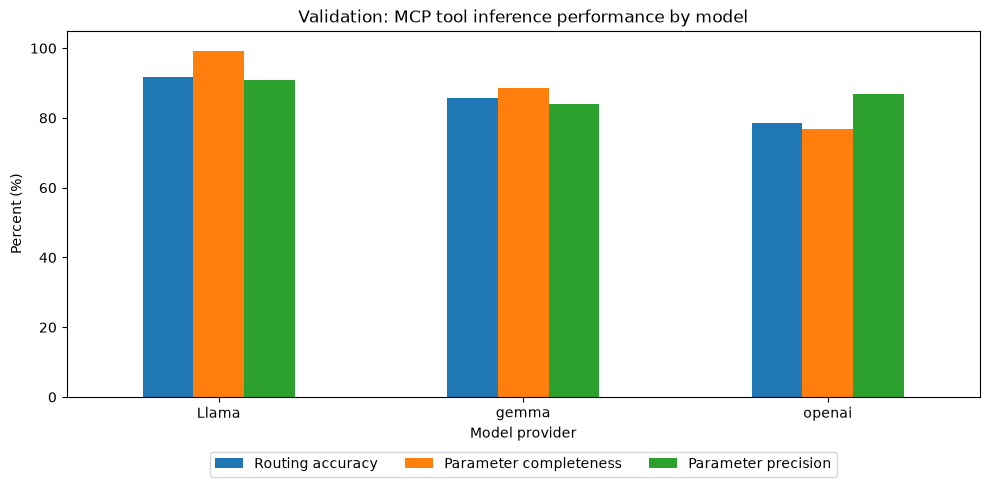

In [48]:
# Roll the per-turn scores up to one summary row per model.
def aggregate_metrics(scores):
    out=[]
    for alias,part in scores.groupby('model_alias'):
        eligible=part[part.required_param_n.gt(0)]      # rows with actual parameters (for pooled metrics)
        no_tool=part[part.status.eq('no_tool_case')]    # clarify/refuse no-tool rows
        total_req=eligible.required_param_n.sum()
        total_pred=eligible.predicted_param_n.sum()
        out.append({'model':alias,'evaluated_turns':len(part),
          # Share of responses that parsed as valid JSON.
          'valid_json_rate_pct':100*part.api_status.eq('ok').mean(),
          # Mean of per-row routing correctness.
          'tool_routing_accuracy_pct':100*part.routing_correct.mean(),
          # Micro-pooled completeness: matched required keys / all required keys.
          'parameter_completeness_weighted_pct':
              100*eligible.matched_required_keys.sum()/total_req if total_req else np.nan,
          # Micro-pooled precision: correctly valued keys / all predicted keys.
          'parameter_precision_weighted_pct':
              100*eligible.correct_predicted_values.sum()/total_pred if total_pred else np.nan,
          # Macro (row-mean) versions reported alongside for transparency.
          'parameter_completeness_row_mean_pct':part.completeness_pct.mean(),
          'parameter_precision_row_mean_pct':part.precision_pct.mean(),
          # Accuracy on the no-tool clarification/refusal cases.
          'no_tool_case_accuracy_pct':100*no_tool.full_match.mean() if len(no_tool) else np.nan,
          # Share of turns that were an exact full match.
          'full_json_match_pct':100*part.full_match.mean()})
    return pd.DataFrame(out).sort_values('model')

if not scores_long.empty:
    summary=aggregate_metrics(scores_long)
    display(summary.round(2))
    summary.to_csv(OUT/'validation_model_summary.csv',index=False)
    # Grouped bar chart of the three headline metrics per model.
    plotcols=['tool_routing_accuracy_pct','parameter_completeness_weighted_pct',
              'parameter_precision_weighted_pct']
    ax=summary.set_index('model')[plotcols].plot(kind='bar',figsize=(10,5))
    ax.set_ylim(0,105);ax.set_ylabel('Percent (%)')
    ax.set_title('Validation: MCP tool inference performance by model')
    ax.set_xlabel('Model provider');ax.legend(['Routing accuracy','Parameter completeness','Parameter precision'],
                                             loc='upper center',bbox_to_anchor=(.5,-.13),ncol=3)
    plt.xticks(rotation=0);plt.tight_layout()
    plt.savefig(OUT/'validation_model_comparison.png',dpi=160,bbox_inches='tight');plt.show()
else:
    print('Run actual validation inference first; no model performance is available.')

## Per-model: prompts where ALL expected parameters were captured

For every validation prompt and every model we answer a single **yes/no**: did the
model supply **all** the required parameter paths present in the reference
`reference_tool_calls_json` for that turn? "Yes" means zero missing required paths
(i.e. parameter completeness = 100% for that row). This is about *capturing* every
expected field, not about getting its value right (that is precision) and not about
routing to the right tools.

No-tool rows (clarify/refuse with empty reference calls) have no parameters to
capture, so they are reported separately and excluded from the yes/no denominator.

In [ ]:
# Per-row yes/no on TWO questions, per model, for the validation set:
#   (A) COMPLETENESS capture: did the model supply EVERY required parameter path?
#   (B) VALUE precision:      were ALL the values the model extracted correct?
# Both reuse the scorer's existing per-row diagnostics:
#   required_param_n  = number of required parameter paths in the reference call(s)
#   missing_keys      = required paths the model did NOT supply   (hurts completeness)
#   predicted_param_n = number of parameter paths the model DID supply
#   wrong_values      = shared paths whose value != reference value (hurts precision)
#   extra_keys        = hallucinated paths not in the reference    (hurts precision)
if not scores_long.empty:
    sl = scores_long.copy()

    # ---- (A) All required parameters captured? (presence only) ----
    sl['has_required_params'] = sl['required_param_n'] > 0
    def _all_captured(r):
        if not r['has_required_params']:
            return np.nan                      # no params to capture -> not applicable
        return len(r['missing_keys']) == 0     # True only if nothing required is missing
    sl['all_params_captured'] = sl.apply(_all_captured, axis=1)
    sl['all_params_captured_label'] = sl['all_params_captured'].map(
        {True: 'yes', False: 'no'}).fillna('n/a (no params)')

    # ---- (B) All extracted values correct? (precision = 100%) ----
    # "Applicable" means the model actually produced some parameter paths to judge.
    sl['has_predicted_params'] = sl['predicted_param_n'] > 0
    def _all_values_correct(r):
        if not r['has_predicted_params']:
            return np.nan                      # model extracted no params -> not applicable
        # yes only if NO wrong values AND NO hallucinated/extra paths among what it predicted.
        return (len(r['wrong_values']) == 0) and (len(r['extra_keys']) == 0)
    sl['all_values_correct'] = sl.apply(_all_values_correct, axis=1)
    sl['all_values_correct_label'] = sl['all_values_correct'].map(
        {True: 'yes', False: 'no'}).fillna('n/a (no params predicted)')

    # ---- Per-model rollups ----
    rows = []
    for alias, part in sl.groupby('model_alias'):
        # (A) denominator: rows where the reference expects parameters.
        appl_cap = part[part['has_required_params']]
        cap_yes = int(appl_cap['all_params_captured'].sum())
        cap_total = int(len(appl_cap))
        # (B) denominator: rows where the model predicted parameters.
        appl_val = part[part['has_predicted_params']]
        val_yes = int(appl_val['all_values_correct'].sum())
        val_total = int(len(appl_val))
        rows.append({
            'model': alias,
            # (A) completeness / capture
            'prompts_with_params': cap_total,
            'all_params_captured_YES': cap_yes,
            'all_params_captured_NO': cap_total - cap_yes,
            'all_params_captured_pct': round(100 * cap_yes / cap_total, 2) if cap_total else np.nan,
            # (B) value precision
            'prompts_with_predicted_params': val_total,
            'all_values_correct_YES': val_yes,
            'all_values_correct_NO': val_total - val_yes,
            'all_values_correct_pct': round(100 * val_yes / val_total, 2) if val_total else np.nan,
        })
    all_captured_summary = pd.DataFrame(rows).sort_values('model')
    print('Per-model yes/no — validation set')
    print('  (A) all required parameters captured   (B) all extracted values correct')
    display(all_captured_summary)
    all_captured_summary.to_csv(OUT/'validation_all_params_captured_summary.csv', index=False)

    # ---- Per-turn detail (one row per turn x model) ----
    detail_cols = ['turn_id','conversation_id','family_id','model_alias','expected_behavior',
                   'required_param_n','matched_required_keys','missing_keys',
                   'all_params_captured_label',
                   'predicted_param_n','correct_predicted_values','wrong_values','extra_keys',
                   'all_values_correct_label']
    all_captured_detail = sl[detail_cols].sort_values(['turn_id','model_alias'])
    display(all_captured_detail.head(15))
    all_captured_detail.to_csv(OUT/'validation_all_params_captured_detail.csv', index=False)
else:
    print('Run validation inference and scoring first; no rows to evaluate.')

## Statistical comparisons and error inspection (optional, after validation)

The models see the **same** validation cases, so paired comparisons are appropriate. McNemar's exact test uses per-conversation success, not independent samples. With 20 synthetic scenario families, p-values are exploratory and should be interpreted with family dependence in mind.

In [51]:
if not scores_long.empty:
    # Collapse to per-conversation success (all turns routed correctly) for each model.
    conversation_success=scores_long.groupby(['model_alias','conversation_id']).routing_correct.all().unstack(0)
    from itertools import combinations
    comparisons=[]
    # Paired comparison for each model pair using discordant conversations (McNemar-style).
    for a,b in combinations(conversation_success.columns,2):
        both=conversation_success[[a,b]].dropna()
        a_only=int((both[a]&~both[b]).sum())   # A right, B wrong
        b_only=int((~both[a]&both[b]).sum())   # B right, A wrong
        discordant=a_only+b_only
        # Exact binomial (McNemar) p-value on the discordant pairs; 1.0 if none disagree.
        pval=binomtest(min(a_only,b_only),discordant,p=.5).pvalue if discordant else 1.
        comparisons.append({'model_A':a,'model_B':b,'paired_conversations':len(both),
                            'A_only_correct':a_only,'B_only_correct':b_only,
                            'difference_B_minus_A_pct':100*(both[b].mean()-both[a].mean()),
                            'exact_McNemar_p':pval})
    display(pd.DataFrame(comparisons))
    # Inspect a sample of non-full-match rows to see where models went wrong.
    errors=scores_long[~scores_long.full_match]
    display(errors[['turn_id','model_alias','api_status','missing_keys','extra_keys',
                    'wrong_values']].head(15))

,model_A,model_B,paired_conversations,A_only_correct,B_only_correct,difference_B_minus_A_pct,exact_McNemar_p
0,Llama,gemma,80,11,6,-6.25,0.332306
1,Llama,openai,80,13,2,-13.75,0.007385
2,gemma,openai,80,10,4,-7.50,0.179565


,turn_id,model_alias,api_status,missing_keys,extra_keys,wrong_values
12,P2P-0062-T01,gemma,ok,[],[get_purchase_order[0].@result_binding],[]
13,P2P-0069-T01,gemma,ok,[],[get_purchase_order[0].@result_binding],[]
14,P2P-0072-T01,gemma,ok,[],[get_purchase_order[0].@result_binding],[]
15,P2P-0076-T01,gemma,ok,[],[get_purchase_order[0].@result_binding],[]
20,P2P-0102-T01,gemma,ok,[],"[check_approval_authority[0].@result_binding, ...",[]
21,P2P-0109-T01,gemma,ok,[],"[check_approval_authority[0].@result_binding, ...",[]
22,P2P-0112-T01,gemma,ok,[],"[check_approval_authority[0].@result_binding, ...",[]
23,P2P-0116-T01,gemma,ok,[],"[check_approval_authority[0].@result_binding, ...",[]
24,P2P-0122-T01,gemma,ok,[],[get_purchase_order[0].@result_binding],[]
26,P2P-0132-T01,gemma,ok,[],[get_purchase_order[0].@result_binding],[]


## Final test evaluation — run **once** after validation decisions are frozen

Use `RUN_FINAL_TEST=True` in Step 0, then execute the cell below. The system prompt is not changed. Keep a separate results file; do not tune the prompt after viewing test outcomes.

In [ ]:
# Final test run — gated behind RUN_FINAL_TEST so it only happens once, after freezing settings.
# Uses the same concurrent all-three-models runner (and same gold REF printout) as validation.
test_prediction_frames={}
if RUN_FINAL_TEST:
    try:test_prediction_frames=run_all_models('test',MAX_TEST_ROWS)
    except Exception as e:print('Final test run failed:',type(e).__name__,str(e)[:200])
else:
    print('Final test remains locked.')


Final test remains locked.


## Save reproducibility metadata and download outputs

This cell does not expose API secrets. Results remain in Colab's temporary runtime unless downloaded or saved to Drive. Save the notebook itself to Google Drive before leaving.

In [ ]:
# Collect reproducibility metadata: data provenance, split sizes, few-shot selection, prompt hash, models.
metadata={'dataset_source':source,'dataset_sha256':DATA_SHA256,
 'seed':SEED,'train_turns':len(train_df),'validation_turns':len(val_df),
 'test_turns':len(test_df),'train_conversations':train_df.conversation_id.nunique(),
 'validation_conversations':val_df.conversation_id.nunique(),
 'test_conversations':test_df.conversation_id.nunique(),
 'fewshot_conversations':selected_conversations,'system_prompt_sha256':prompt_hash,
 'model_registry':{k:{'provider':v['provider'],'model':v['model']} for k,v in MODELS.items()},
 'validation_enabled':RUN_VALIDATION,'final_test_enabled':RUN_FINAL_TEST}
(OUT/'experiment_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')

# Zip the entire output folder for easy download/archival.
import shutil
archive=shutil.make_archive(str(OUT),'zip',root_dir=str(OUT))
print('Exported:',archive)
# In Colab, optionally trigger a browser download of the archive (commented out by default).
try:
    from google.colab import files
    # Uncomment to download the archive automatically:
    # files.download(archive)
except ImportError:pass

Exported: /Users/asastry/Downloads/capstone/interim_submission/mcp_capstone_outputs.zip
